# EO4FLOOD precipitation

Nine products measure rainfall over nine river basins in different ways. The Ebro example brings together
whole-record statistics, daily and event maps, point and domain-mean time series, monthly climatology,
annual totals, and a comparison of the products. The arrays are read directly from the public Zarr
assets identified by the EO4FLOOD STAC items.

There are 77 basin–product combinations. CHIRPS and GSMaP do not cover the Torne, which lies between
65 and 70 degrees north. Grid spacing varies by product; the products share a study domain, not an identical grid.

| Product family | Source and interpretation | Sampling in this delivery |
|---|---|---|
| IMERG Early, Late, Final | NASA GPM; half-hourly source aggregated to hourly amounts | Hourly |
| GSMaP NRT, MVK, Gauge | JAXA precipitation; Gauge includes gauge adjustment | Hourly |
| CHIRPS | Rain-gauge-blended precipitation | Daily |
| SM2RAIN-ASCAT | Rainfall inferred from satellite soil moisture | Daily |
| ERA5-Land | Reanalysis, with within-day accumulated precipitation | Hourly |

## Rainfall arrays and physical units

One Zarr store holds one basin and one product. `Precipitation` has dimensions
`(time, latitude, longitude)`; `lat` and `lon` contain grid-cell centres in geographic degrees.
The time axis describes each sample's timestamp.

The delivery stores precipitation as **millimetres multiplied by 1,000**, despite the `mm` units
attribute. Multiplication by `1e-3` restores millimetres. Missing values are decoded from the store's
fill metadata. Hourly rainfall amounts are summed to daily totals; daily inputs remain daily.
ERA5-Land is accumulated within the day, so its midnight value is the preceding day's total.
All-missing days remain missing rather than becoming zero.

The September 2026 extraction corrected the IMERG source aggregation and dropped-hour issues in
IMERG and GSMaP. The STAC precipitation assets used here point to the rebuilt mirror.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import s3fs
from urllib.parse import urlparse
import matplotlib.pyplot as plt

s3 = s3fs.S3FileSystem(anon=True, client_kwargs={
    "endpoint_url": "https://s3.waw4-1.cloudferro.com"
})

PRODUCT_URLS = {
    "CHIRPS": "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood_precipitation_zarrs_v2/EO4FLOOD_Precipitation_CHIRPS_ebro.zarr",
    "ERA5": "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood_precipitation_zarrs_v2/EO4FLOOD_Precipitation_ERA5_ebro.zarr",
    "GSMAP_Gauge": "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood_precipitation_zarrs_v2/EO4FLOOD_Precipitation_GSMAP_Gauge_ebro.zarr",
    "GSMAP_MVK": "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood_precipitation_zarrs_v2/EO4FLOOD_Precipitation_GSMAP_MVK_ebro.zarr",
    "GSMAP_NRT": "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood_precipitation_zarrs_v2/EO4FLOOD_Precipitation_GSMAP_NRT_ebro.zarr",
    "IMERG_ER": "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood_precipitation_zarrs_v2/EO4FLOOD_Precipitation_IMERG_ER_ebro.zarr",
    "IMERG_FR": "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood_precipitation_zarrs_v2/EO4FLOOD_Precipitation_IMERG_FR_ebro.zarr",
    "IMERG_LR": "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood_precipitation_zarrs_v2/EO4FLOOD_Precipitation_IMERG_LR_ebro.zarr",
    "SM2RAIN_ASCAT": "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood_precipitation_zarrs_v2/EO4FLOOD_Precipitation_SM2RAIN_ASCAT_ebro.zarr"
}
BASIN = "Ebro"
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True})

PRODUCT = "CHIRPS"
START, END = "2016-01-01", "2024-12-31"
EVENT_START, EVENT_END = "2021-12-05", "2021-12-15"
MAP_DAY = "2021-12-10"
POINT_LAT, POINT_LON = 41.65, -0.88

url = PRODUCT_URLS[PRODUCT]
ds = xr.open_zarr(s3.get_mapper(urlparse(url).path.lstrip("/")), consolidated=False, chunks=None)
ds

<xarray.Dataset> Size: 153MB
Dimensions:        (time: 3288, latitude: 77, longitude: 151)
Coordinates:
  * time           (time) datetime64[ns] 26kB 2016-01-01 ... 2024-12-31
Dimensions without coordinates: latitude, longitude
Data variables:
    Precipitation  (time, latitude, longitude) float32 153MB ...
    lon            (longitude) float32 604B ...
    lat            (latitude) float32 308B ...
Attributes:
    title:                       ESA EO4FLOOD project Precipitation input
    product:                     CHIRPS
    basin:                       ebro
    creation_time:               06-Feb-2026 15:45:43
    institution:                 National Research Council  - Research Instit...
    creator_institution_e-mail:  luca.ciabatta@cnr.it
    references:                  Tarpanelli et al., 2025. The Potential of EO...
    temporal_interval:           Jan-01-2016 to Dec-31-2024 23:00
    version:                     Version 1.1
    Conventions:                 CF-1.11-draft
    DOI:                         10.5281/zenodo.17787732
    Acknowledgements:            European Space Agency EO4FLOOD project Contr...

In [2]:
rain = (ds.Precipitation.load() * 1e-3).assign_coords(latitude=ds.lat.values, longitude=ds.lon.values)
rain = rain.sortby("latitude").sortby("longitude")

if PRODUCT == "ERA5":
    daily = rain.where(rain.time.dt.hour == 0, drop=True)
    daily = daily.assign_coords(time=daily.time - np.timedelta64(1, "D"))
else:

    daily = rain.resample(time="1D").sum(min_count=1)
daily = daily.sel(time=slice(START, END)).load()
daily.attrs.update(units="mm/day", long_name=f"{PRODUCT} daily precipitation")
area = daily.mean(["latitude", "longitude"]).to_series()
point = daily.sel(latitude=POINT_LAT, longitude=POINT_LON, method="nearest").to_series()
pd.DataFrame({"domain_mean_mm_day": area, "point_mm_day": point}).describe()

,domain_mean_mm_day,point_mm_day
count,3288.000000,3288.000000
mean,1.723993,0.993293
std,3.036388,2.814737
min,0.000000,0.000000
25%,0.024362,0.000000
50%,0.365664,0.000000
75%,1.976995,0.000000
max,28.617020,33.208000


## Whole-record rainfall statistics

The mean map describes the typical rainfall pattern. The maximum map identifies the strongest daily
amount at each grid cell, while wet-day frequency measures the fraction of observed days with at
least 1 mm. Mean annual totals describe the overall water input.

Spatial averages are simple means over valid grid cells in the delivered domain. They are not
catchment-area-weighted means or a separate delineation of the river basin. Missing days do not count as dry days.

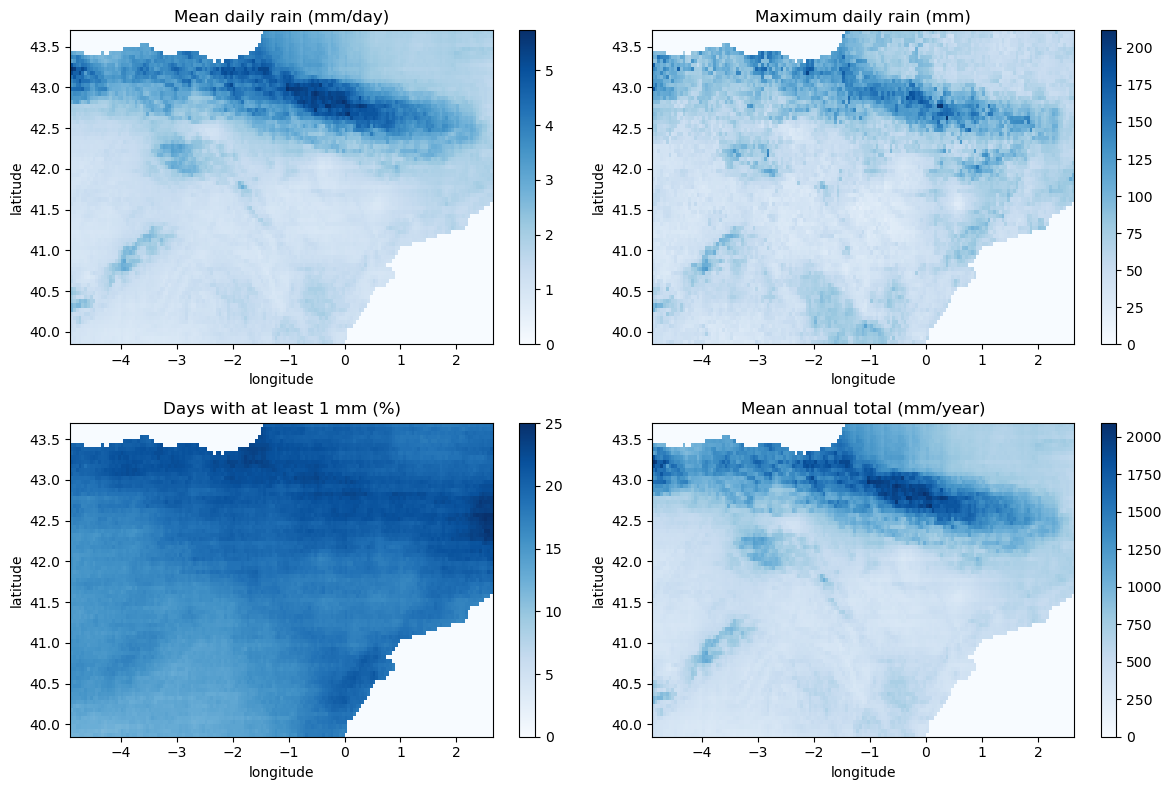

In [3]:
annual_maps = daily.resample(time="YS").sum(min_count=1)
fields = [daily.mean("time"), daily.max("time"),
          (daily >= 1).where(daily.notnull()).mean("time") * 100,
          annual_maps.mean("time")]
titles = ["Mean daily rain (mm/day)", "Maximum daily rain (mm)",
          "Days with at least 1 mm (%)", "Mean annual total (mm/year)"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for field, title, ax in zip(fields, titles, axes.flat):
    field.plot(ax=ax, x="longitude", y="latitude", cmap="Blues", cbar_kwargs={"label": ""})
    ax.set_title(title)
fig.tight_layout()
plt.show()

## A single day and a rainfall event

Two views of the same field tell different stories. The single day shows the daily spatial pattern;
the event sums several days, which is important for flood-generating rainfall. The daily maximum
within the event identifies where the most intense daily amounts occurred. This example spans
5–15 December 2021, with a single-day map for 10 December.

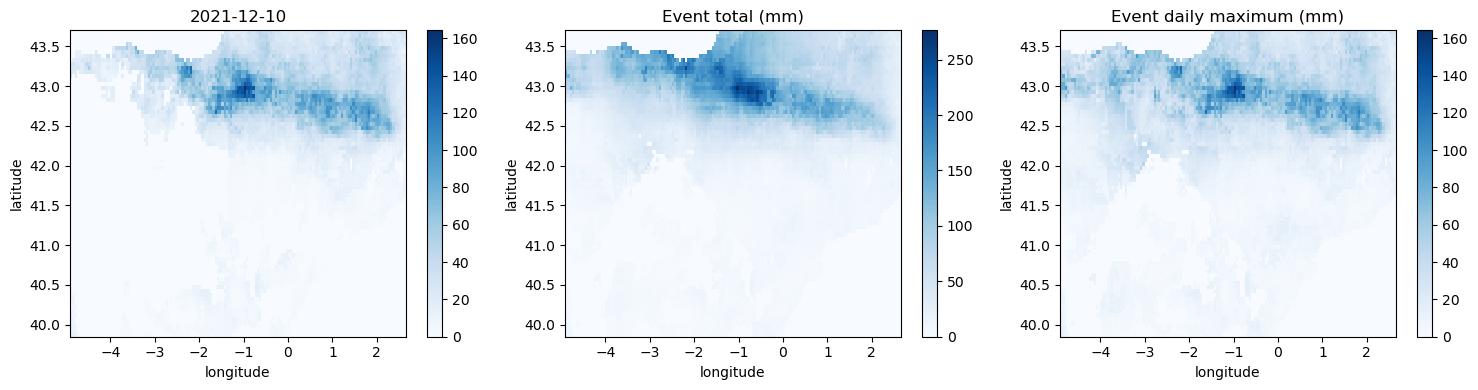

In [4]:
event = daily.sel(time=slice(EVENT_START, EVENT_END))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for field, title, ax in zip(
    [daily.sel(time=MAP_DAY), event.sum("time", min_count=1), event.max("time")],
    [MAP_DAY, "Event total (mm)", "Event daily maximum (mm)"], axes
):
    field.plot(ax=ax, x="longitude", y="latitude", cmap="Blues", cbar_kwargs={"label": ""})
    ax.set_title(title)
fig.tight_layout()
plt.show()

## Domain and point time series

The spatial mean smooths local variability and reveals the seasonal cycle, while the series at a
point keeps sharper rainfall peaks. The example point lies near Zaragoza. Monthly totals describe
seasonal water input; annual totals show the differences between years.

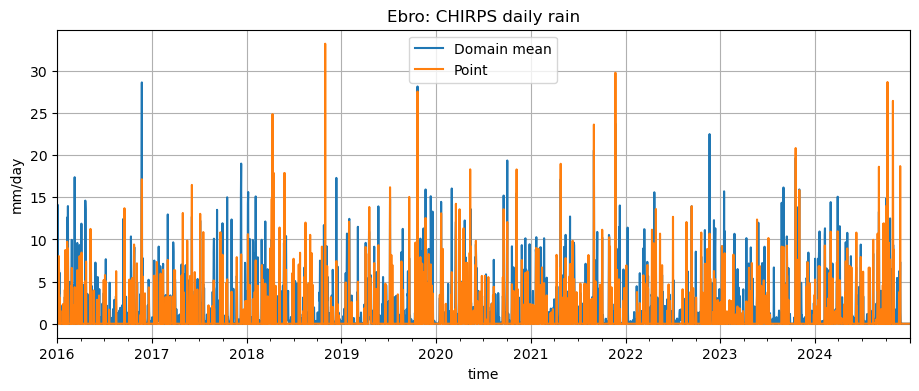

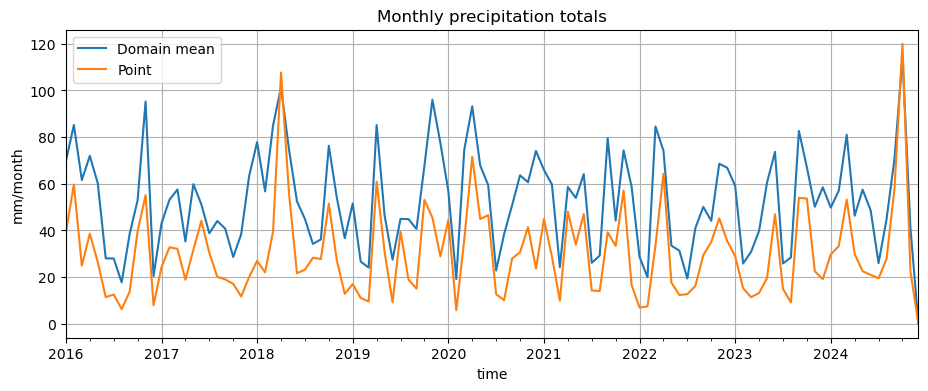

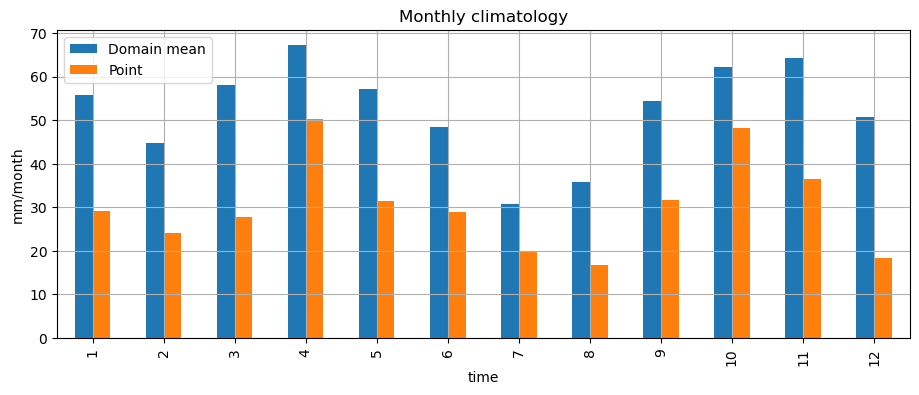

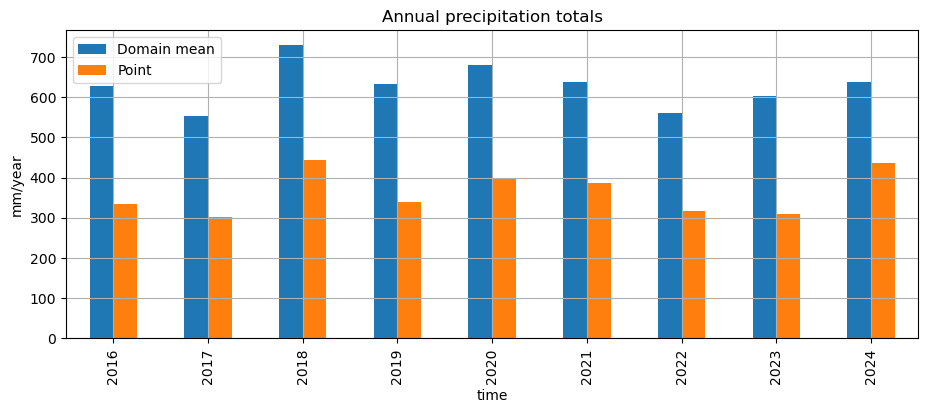

In [5]:
series = pd.DataFrame({"Domain mean": area, "Point": point})
series.plot(ylabel="mm/day", title=f"{BASIN}: {PRODUCT} daily rain")
plt.show()
monthly = series.resample("MS").sum(min_count=1)
monthly.plot(ylabel="mm/month", title="Monthly precipitation totals")
plt.show()
monthly.groupby(monthly.index.month).mean().plot.bar(ylabel="mm/month", title="Monthly climatology")
plt.show()
annual = series.resample("YS").sum(min_count=1)
annual.index = annual.index.year
annual.plot.bar(ylabel="mm/year", title="Annual precipitation totals")
plt.show()

## Monthly climatology and annual maps

The climatology averages each calendar month's total over the record, answering when it usually
rains. Annual maps answer how the amount and spatial pattern vary from year to year.

Every available year is represented, including partial ones. Gaps in the source archive make totals
underestimates; for example, the delivery notes identify missing IMERG Final days in 2020. These
are totals of the available observations, without filling the gaps.

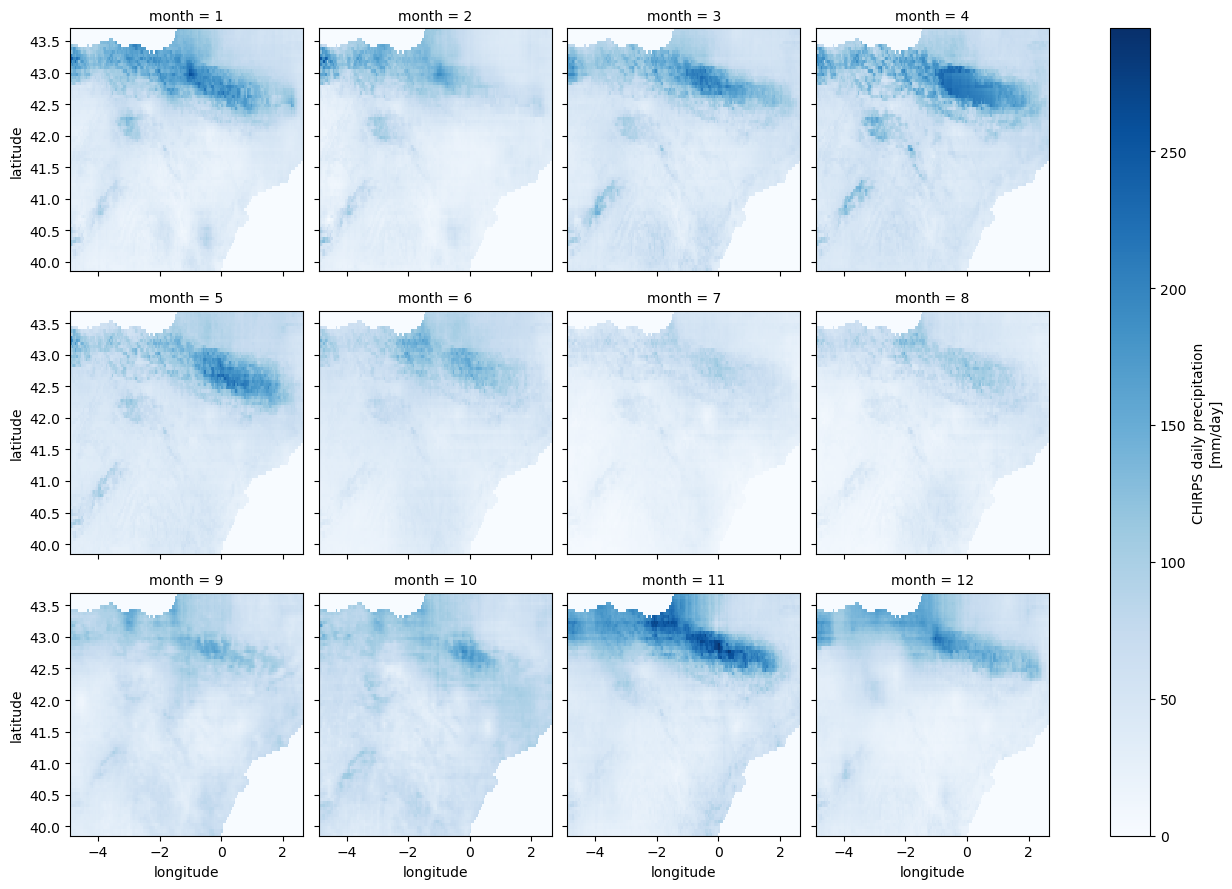

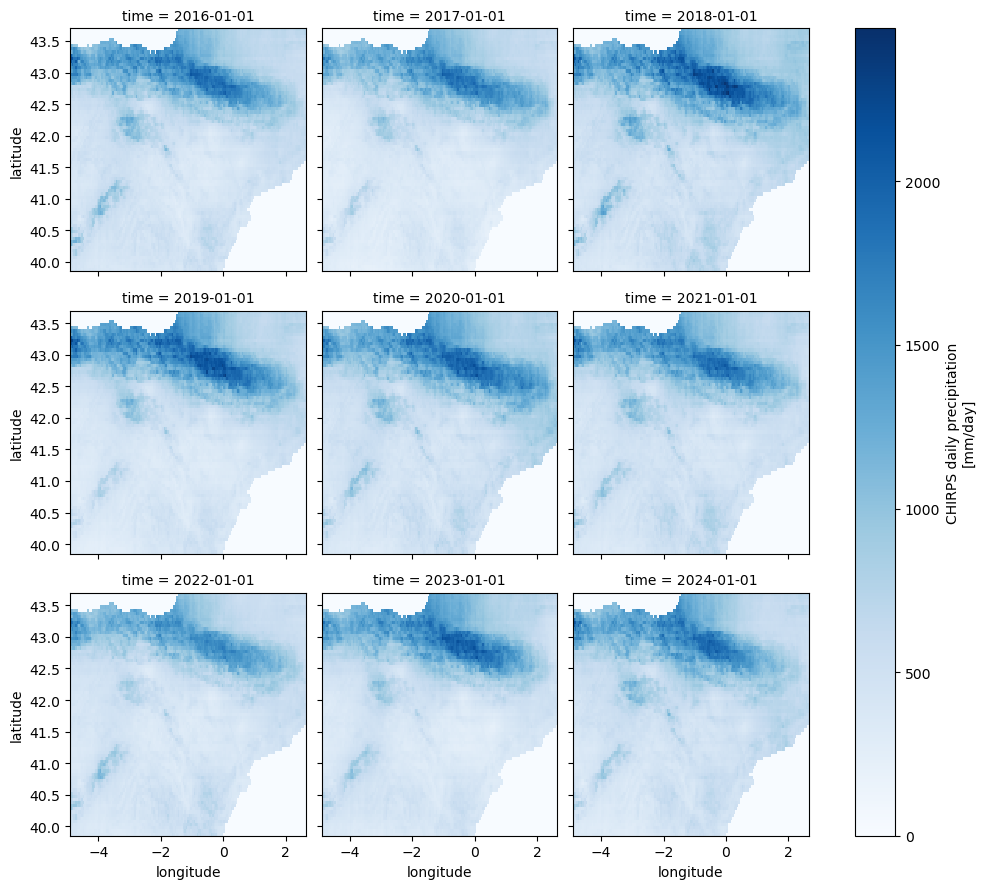

In [6]:
monthly_maps = daily.resample(time="MS").sum(min_count=1).groupby("time.month").mean("time")
monthly_maps.plot(x="longitude", y="latitude", col="month", col_wrap=4, cmap="Blues")
plt.show()
annual_maps.plot(x="longitude", y="latitude", col="time", col_wrap=3, cmap="Blues")
plt.show()

## Comparison of all nine precipitation products

The same basin is viewed through all nine products: monthly series, annual totals, cumulative
curves, and mean annual maps. Each product is averaged on its own grid before the time series
are compared. Correlation, bias and RMSE use only dates observed in both a product and the CHIRPS
reference. CHIRPS is a comparison reference here, not an independent ground-truth validation.

The spread between products shows the sensitivity of the rainfall estimate to product choice.
A product separating from the others at a particular date can reflect changes in its processing
as well as differences in how the products observe rainfall.

,mean_mm_day,correlation,bias_percent,rmse_mm_day
product,,,,
CHIRPS,1.723993,1.000000,0.000000,0.000000
ERA5,1.851762,0.681273,7.378554,2.327805
GSMAP_Gauge,1.579015,0.714804,-8.409482,2.158604
GSMAP_MVK,1.395803,0.735583,-19.036615,2.112293
GSMAP_NRT,1.514810,0.726698,-12.133635,2.121653
IMERG_ER,2.056847,0.783056,19.307137,2.277637
IMERG_FR,1.916379,0.788790,11.403572,2.036072
IMERG_LR,1.975702,0.767658,14.602507,2.293616
SM2RAIN_ASCAT,1.700069,0.590302,-1.387721,2.487490


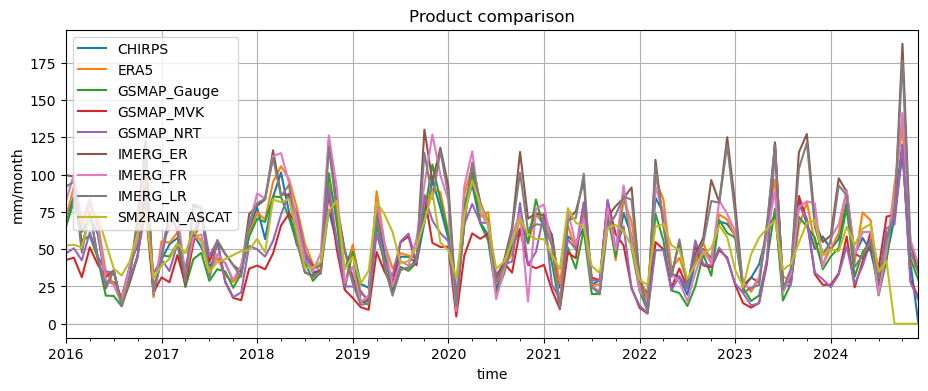

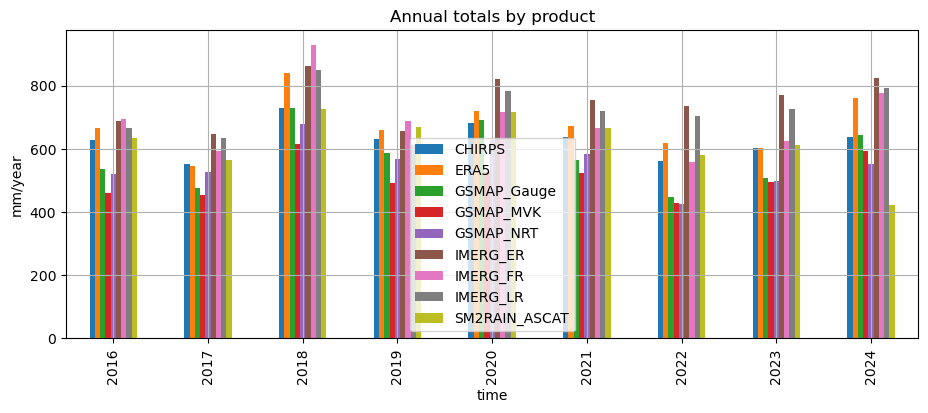

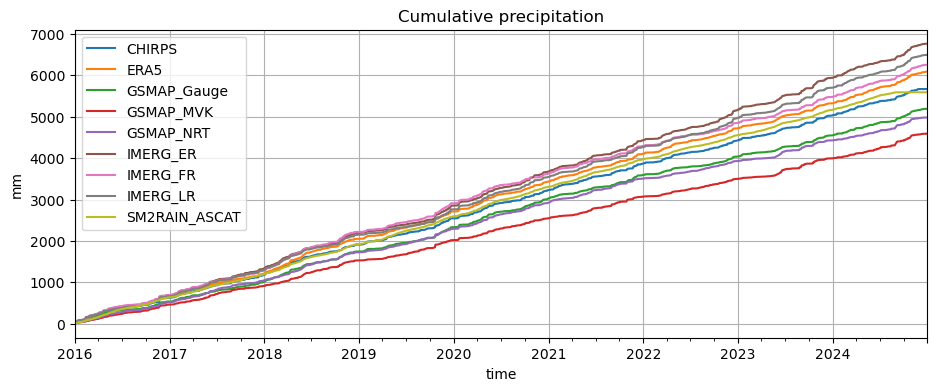

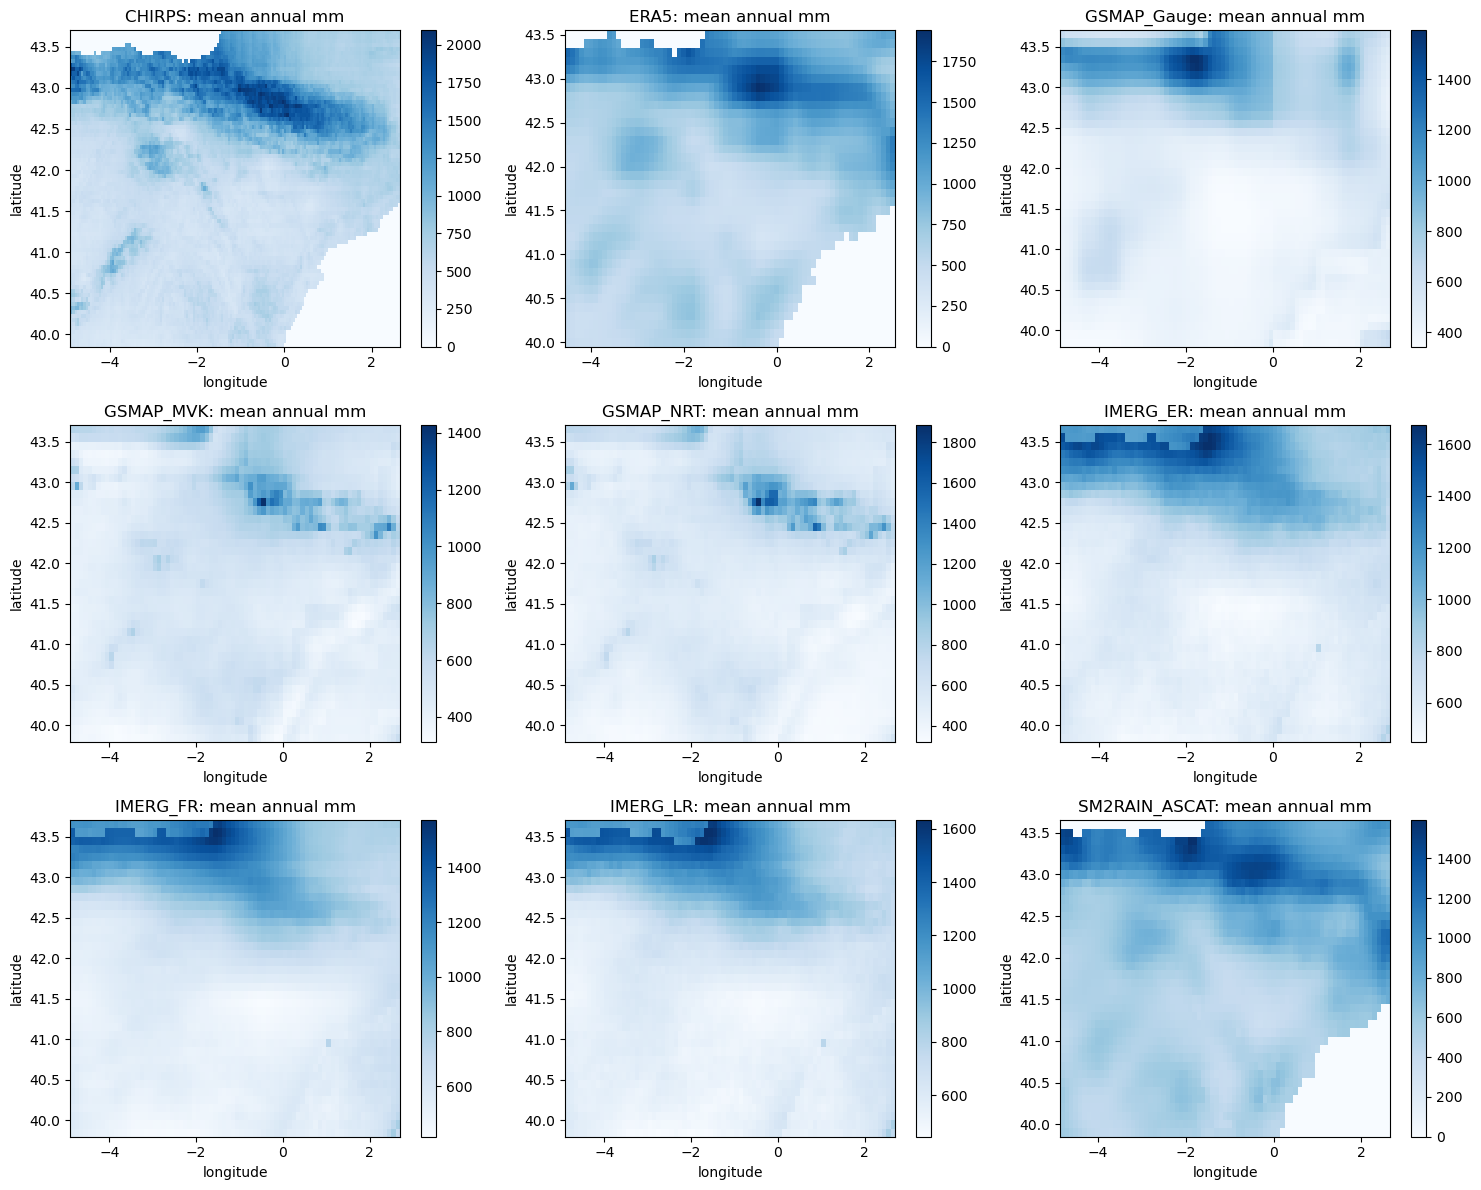

In [7]:
PRODUCTS = ["CHIRPS", "ERA5", "GSMAP_Gauge", "GSMAP_MVK", "GSMAP_NRT",
            "IMERG_ER", "IMERG_FR", "IMERG_LR", "SM2RAIN_ASCAT"]
comparison = {}
mean_annual_maps = {}
for product in PRODUCTS:
    file = PRODUCT_URLS[product]
    with xr.open_zarr(s3.get_mapper(urlparse(file).path.lstrip("/")), consolidated=False, chunks=None) as other:
        values = (other.Precipitation.load() * 1e-3).assign_coords(latitude=other.lat.values, longitude=other.lon.values)
        values = values.sortby("latitude").sortby("longitude")
        if product == "ERA5":
            amounts = values.where(values.time.dt.hour == 0, drop=True)
            amounts = amounts.assign_coords(time=amounts.time - np.timedelta64(1, "D"))
        else:
            amounts = values.resample(time="1D").sum(min_count=1)
        amounts = amounts.sel(time=slice(START, END)).load()
        comparison[product] = amounts.mean(["latitude", "longitude"]).to_series()
        mean_annual_maps[product] = amounts.resample(time="YS").sum(min_count=1).mean("time")
compare = pd.DataFrame(comparison)
reference = "CHIRPS"
rows = []
for product in PRODUCTS:
    pair = compare[[product]].rename(columns={product: "value"}).join(compare[reference].rename("reference")).dropna()
    rows.append({"product": product, "mean_mm_day": pair.value.mean(),
                 "correlation": pair.value.corr(pair.reference),
                 "bias_percent": 100 * (pair.value.mean() / pair.reference.mean() - 1),
                 "rmse_mm_day": np.sqrt(((pair.value - pair.reference) ** 2).mean())})
display(pd.DataFrame(rows).set_index("product"))
compare.resample("MS").sum(min_count=1).plot(ylabel="mm/month", title="Product comparison")
plt.show()
annual_comparison = compare.resample("YS").sum(min_count=1)
annual_comparison.index = annual_comparison.index.year
annual_comparison.plot.bar(ylabel="mm/year", title="Annual totals by product")
plt.show()
compare.cumsum().plot(ylabel="mm", title="Cumulative precipitation")
plt.show()
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for (product, field), ax in zip(mean_annual_maps.items(), axes.flat):
    field.plot(ax=ax, x="longitude", y="latitude", cmap="Blues", cbar_kwargs={"label": ""})
    ax.set_title(f"{product}: mean annual mm")
fig.tight_layout()
plt.show()

In [ ]:
ds.close()